In [1]:
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import os
import yaml

In [2]:
#Load the configuration file
with open("../config/config.yaml", "r") as f:
    config = yaml.safe_load(f)

raw_data_path = "../"+config["paths"]["raw_data_dir"]    

## Sampling the data

I will sample the data to make it light in resources, as the original dataset is fairly large.

In [3]:
# Retrieve the path and file names for all the parquet files

def get_parquet_from_path(path):
    parquet_files = []
    for (dir_path, _, files) in os.walk(path):
        for f in files:
            if f.endswith(".parquet"):
                parquet_files.append(os.path.join(dir_path, f)) 
    return parquet_files

In [4]:
# Check the method get_parquet_from_path() output

file_path = get_parquet_from_path(raw_data_path)
(print(file_path))


['../data/raw/cscareerquestionsEU_comments.parquet', '../data/raw/SoftwareEngineering_comments.parquet', '../data/raw/cscareerquestions_comments.parquet', '../data/raw/SoftwareEngineering_submissions.parquet', '../data/raw/datascience_submissions.parquet', '../data/raw/cybersecurity_submissions.parquet', '../data/raw/QualityAssurance_comments.parquet', '../data/raw/datascience_comments.parquet', '../data/raw/QualityAssurance_submissions.parquet', '../data/raw/cscareerquestionsEU_submissions.parquet', '../data/raw/cscareerquestions_submissions.parquet', '../data/raw/dataengineering_submissions.parquet', '../data/raw/cybersecurity_comments.parquet', '../data/raw/dataengineering_comments.parquet']


### Core Sampler

In [5]:
import json
import random
def sample_parquet_file_to_json(file_path, desired_samples = 10000):
    file_count = 0
    for file_number in range(len(file_path)):
        file_name = os.path.splitext(os.path.basename(file_path[file_number]))[0]
        # Read the paraquet file metadata
        metadata = pq.read_metadata(file_path[file_number])
        # Total number of samples and target retention number
        total_samples = metadata.num_rows
        # Perform random sampling
        if total_samples <= desired_samples:
            table = pq.read_table(file_path[file_number])
            data = table.to_pylist()
        else:
            random_indices = random.sample(range(total_samples), desired_samples)
            random_indices.sort()  # Sort the indices to speed up batch reading
            table = pq.read_table(file_path[file_number])
          
            # Take a batch based on the random  indices
            sampled_table = table.take(random_indices)
            selected_samples = sampled_table.to_pylist()
        # Write the sampled results to a new JSON file
        output_dir_path = ("../data/samples")
        os.makedirs(output_dir_path, exist_ok=True)
        with open(f'{output_dir_path}/{file_name}.json','w', encoding='utf-8') as f:
            json.dump(selected_samples, f, ensure_ascii=False, indent=4, default=str)
        print(f"Random sampling completed for {file_name}, retained {len(selected_samples)} samples.") 
        file_count+=1
    print(f"Done! Sampled {file_count} files")   

In [6]:
#sample_parquet_file_to_json(file_path)

## Cleaning the Data

### Removing Code Blocks

In [7]:
import re

# Needs to be integrated to be done before the json_to_df method as 
# text need to be cleaned before going into a df

def clean_code_snippets(text):
    # 1. Remove multi-line code blocks (``` ... ```)
    # Replaces everything from the first ``` to the next ```, including newlines.
    # [^`]*? ensures we match non-greedily.
    no_blocks = re.sub(r'```[^`]*?```', '', text)
    
    # 2. Remove inline code blocks (` ... `)
    # Replaces everything between single backticks non-greedily.
    clean_text = re.sub(r'`[^`]+?`', '', no_blocks)
    
    return clean_text

In [21]:
from pathlib import Path

data_samples_path = Path("../"+config["paths"]["data_samples_dir"])

def json_to_df(json_path, dataset_type = "submissions", lines = False):
    try:
        json_path = Path(json_path)
        valid_dataset_type = ["submissions", "comments"]
        if dataset_type not in valid_dataset_type:
            raise ValueError(f"Invalid type. Choose from {valid_dataset_type}")

    # Load the json files into a dataframe and add a coulmn that says what subreddit
    # the comment or submission belong to.
    # Merge the dataframes to get a separate comments, or submissions dataframes
    
        tmp_files_list = []  

        selected_files = [file for file in json_path.glob(f"*_{dataset_type}.json") if file.is_file()]
        for file_path in selected_files:
            tmp_file = pd.read_json(file_path, lines = lines)
            tmp_file["subreddit"] = file_path.stem.split("_")[0]
            tmp_files_list.append(tmp_file)
        
            
        files_df = pd.concat(tmp_files_list, ignore_index = True)
        return files_df 
    except ValueError as e:
        print(f"No files found at the current path: {str(json_path)}")
        print(f"Error line: {e}")
        

dataengineering
QualityAssurance
cybersecurity
cscareerquestionsEU
datascience
cscareerquestions
SoftwareEngineering


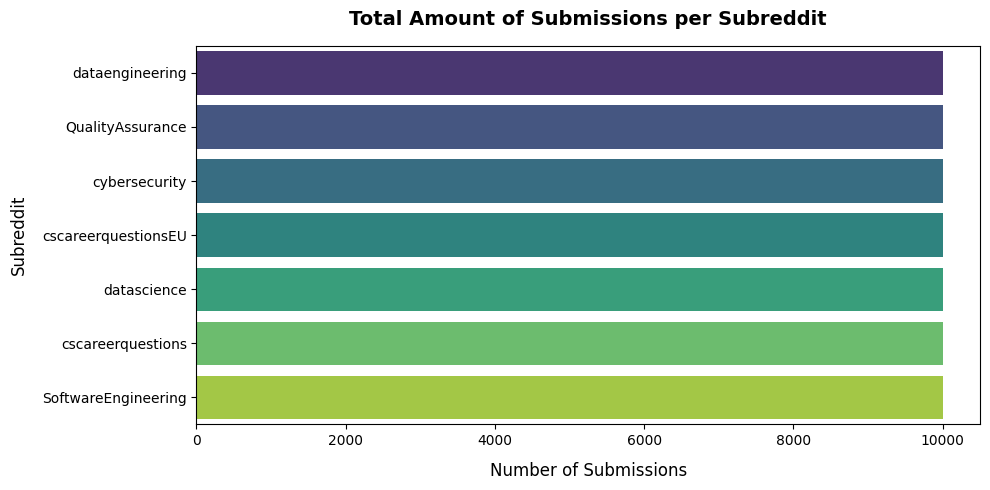

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load your master submissions DataFrame using your function
submissions_df = json_to_df(data_samples_path,dataset_type="submissions")

# 2. Count the submissions per subreddit and sort them in descending order
# Sorting ensures the chart has a clean visual hierarchy!
subreddit_counts = submissions_df['subreddit'].value_counts().reset_index()
subreddit_counts.columns = ['subreddit', 'submission_count']

# 3. Create the plot using subplots (avoids using .figure())
fig, ax = plt.subplots(figsize=(10, 5))

# 4. Draw the horizontal bar chart
sns.barplot(
    data=subreddit_counts,
    x='submission_count',
    y='subreddit',
    ax=ax,
    palette='viridis',
    hue='subreddit',
    legend=False
)

# 5. Clean up typography and ensure labels are highly readable
ax.set_title('Total Amount of Submissions per Subreddit', fontsize=14, pad=15, fontweight='bold')
ax.set_xlabel('Number of Submissions', fontsize=12, labelpad=10)
ax.set_ylabel('Subreddit', fontsize=12, labelpad=10)

# Adjust layout automatically so labels are never clipped or truncated
plt.tight_layout()

# 6. Save the plot as an image asset directly to your working directory
plt.savefig('subreddit_submissions_distribution.png', dpi=300, bbox_inches='tight')